# Módulo 2 · 02 · Análisis descriptivo

Balance de clases, iluminación, ángulo y tipo de vehículo, duplicados e hipótesis sobre qué clases costará separar.

In [1]:
# parameters
DEMO = False

In [2]:
import sys
from pathlib import Path
RAIZ = Path.cwd().resolve().parents[1]
sys.path[:0] = [str(RAIZ), str(RAIZ / "modulo2_distraccion")]

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common.seeds import fijar_semilla
import m2lib, m2exp

fijar_semilla()
cfg = m2exp.config(demo=DEMO)
CLASES = cfg["datos"]["clases"]
ETIQ = [m2lib.NOMBRES[c] for c in CLASES]
FIG, RES = m2lib.FIGURAS, m2lib.RESULTADOS
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})

In [3]:
from PIL import Image
meta = m2lib.validas()
meta["origen"] = np.where(meta["conductor"].notna(), "State Farm (640×480)", "otro origen")
pd.crosstab(meta["clase"], meta["origen"], margins=True).loc[CLASES + ["All"]]

origen,State Farm (640×480),otro origen,All
clase,,,
safe_driving,1531,148,1679
turning,1187,152,1339
texting_phone,1505,56,1561
talking_phone,1434,79,1513
other_activities,972,212,1184
All,6629,647,7276


## Balance
La clase mayor (conducción segura) tiene 1,4 veces la menor (otras actividades): un desbalance leve que no exige reponderar, pero el F1 macro se reporta junto con la exactitud.

## Iluminación
Brillo medio (canal de luminancia, 0–255) y contraste (desviación estándar) de cada imagen procesada.

brillo  contraste
origen               clase                                  
State Farm (640×480) other_activities   93.500000  79.500000
                     safe_driving       90.300003  78.800003
                     talking_phone      90.800003  79.000000
                     texting_phone      90.500000  79.099998
                     turning            91.199997  77.800003
otro origen          other_activities  118.400002  44.400002
                     safe_driving      116.900002  42.900002
                     talking_phone     122.500000  44.000000
                     texting_phone     124.300003  43.799999
                     turning           119.000000  45.700001

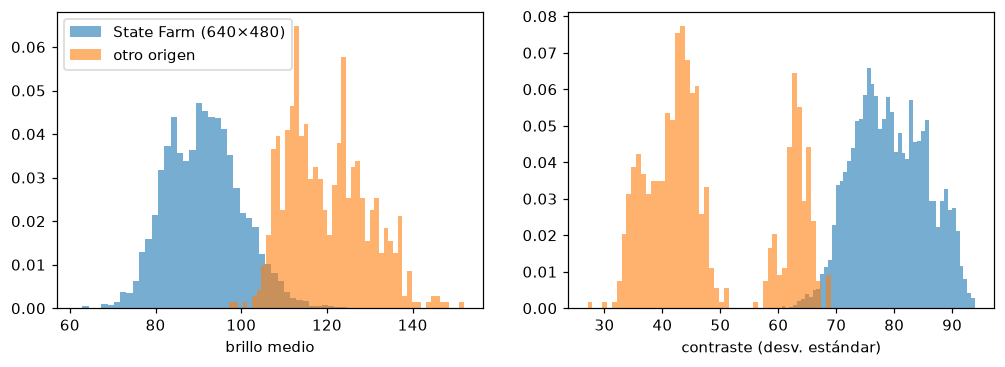

In [4]:
def brillo(a):
    g = np.asarray(Image.open(m2lib.PROC / "imagenes" / a).convert("L"), dtype=np.float32)
    return g.mean(), g.std()
meta[["brillo", "contraste"]] = [brillo(a) for a in meta["archivo"]]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
for o, d in meta.groupby("origen"):
    axs[0].hist(d["brillo"], bins=50, alpha=.6, density=True, label=o)
    axs[1].hist(d["contraste"], bins=50, alpha=.6, density=True, label=o)
axs[0].set_xlabel("brillo medio"); axs[1].set_xlabel("contraste (desv. estándar)"); axs[0].legend()
fig.savefig(FIG / "iluminacion.png")
meta.groupby(["origen", "clase"])[["brillo", "contraste"]].median().round(1)

## Ángulo y tipo de vehículo
State Farm usa una sola cámara fija en el parante derecho de un carro, con el conductor a la izquierda y de perfil. Las imágenes de otro origen son de buses y carros en Bangladesh, con la cámara de frente o desde atrás, volante a la derecha en varios casos y fotos verticales.

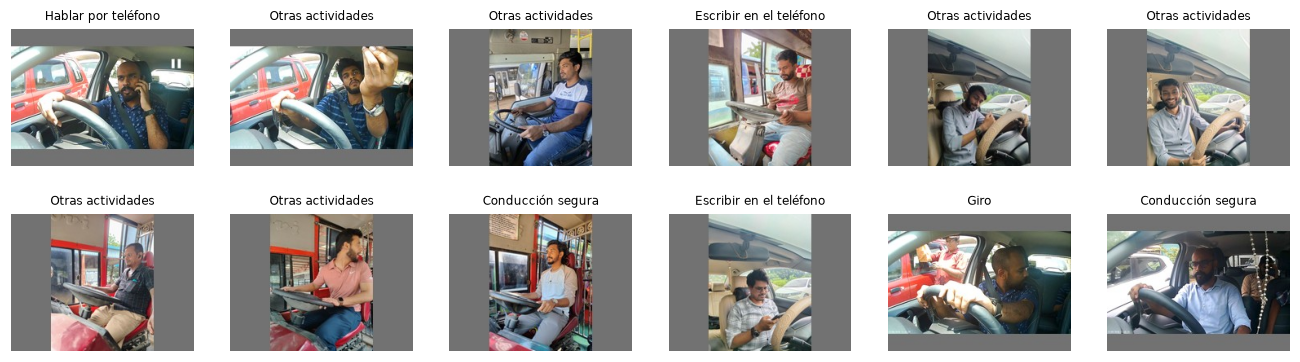

In [5]:
otras = meta[meta.origen == "otro origen"].sample(12, random_state=1)
fig, axs = plt.subplots(2, 6, figsize=(15, 4))
for ax, (_, r) in zip(axs.flat, otras.iterrows()):
    ax.imshow(Image.open(m2lib.PROC / "imagenes" / r.archivo)); ax.set_title(m2lib.NOMBRES[r.clase], fontsize=8); ax.axis("off")
fig.savefig(FIG / "otro_origen.png")

## Duplicados

In [6]:
v = m2lib.cargar_metadatos(); v = v[~v.corrupta]
print("duplicados exactos (mismo sha1):", int(v.sha1.duplicated(keep=False).sum()))
print("imágenes que comparten dHash idéntico:", int(v.dhash.duplicated(keep=False).sum()))
F = m2lib.cargar_caracteristicas(); f = F / np.linalg.norm(F, axis=1, keepdims=True)
S = f @ f.T; np.fill_diagonal(S, -1)
print("imágenes con un vecino de coseno >= 0.96:", int((S.max(1) >= cfg["particion"]["umbral_similitud"]).sum()))

duplicados exactos (mismo sha1): 0
imágenes que comparten dHash idéntico: 1417


imágenes con un vecino de coseno >= 0.96: 6303


## Hipótesis

1. **Escribir y hablar por teléfono se confundirán entre sí**: las dos tienen el teléfono en la mano y difieren solo en si está en la oreja o frente al pecho.
2. **«Otras actividades» será la clase más difícil**: mezcla cuatro comportamientos (radio, beber, peinarse, hablar con el pasajero) que se parecen a conducir seguro o a hablar por teléfono.
3. **«Giro» será fácil en State Farm** porque ahí es «alcanzar algo atrás», una postura muy distinta, **y difícil en las imágenes de otro origen**, donde es girar el volante y se parece a conducir seguro.
4. **El modelo rendirá peor en las imágenes de otro origen**, que son pocas y con otra cámara.
5. **La red preentrenada superará a la red desde cero**: con 26 conductores, una red desde cero tiende a memorizar a las personas y el fondo.

El notebook 06 dice cuáles se confirmaron.